# Notebook 07 - diagnosis: which relationships changed?
We compare **TreeSHAP** feature attributions for a model trained on 2022-2025 against one that also sees 2026, both explained on the 2026 laps. Features whose importance moves are the relationships the regulation change altered. Reads `data/model_table.csv.gz` and `results/model_config.json` (the feature set and parameters chosen in notebook 04).

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb
from f1lap.features import encode_features
from f1lap.models import SEED, CONFIG_PATH, make_xgb

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
cfg = json.load(open(CONFIG_PATH))   # final feature set + tuned params, chosen in notebook 04
df = pd.read_csv('data/model_table.csv.gz')
X_all = encode_features(df, cfg['groups'], cfg['team'])   # one aligned matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
XGB_PARAMS = cfg['xgb_params']
print('Feature set:', cfg['name'], '|', X_all.shape[1], 'features | params:', XGB_PARAMS)

Feature set: + weather (all) | 39 features | params: {'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 400, 'n_estimators': 1000}


### 1. SHAP before vs after seeing 2026
SHAP values come straight from **XGBoost's native `pred_contribs`**, which is the same TreeSHAP algorithm the `shap` library wraps, so there's no extra dependency.

In [2]:
m_pre = make_xgb(**XGB_PARAMS).fit(X_all[df.season < 2026], y_all[df.season < 2026].values)
m_post = make_xgb(**XGB_PARAMS).fit(X_all, y_all.values)
dm = xgb.DMatrix(X_all[df.season == 2026])
def mean_abs_shap(m):
    c = m.get_booster().predict(dm, pred_contribs=True)[:, :-1]   # drop the bias column
    return pd.Series(np.abs(c).mean(0), index=FEATURE_COLS)
shap_cmp = pd.DataFrame({'2022-2025': mean_abs_shap(m_pre), 'incl_2026': mean_abs_shap(m_post)})
shap_cmp['change'] = shap_cmp['incl_2026'] - shap_cmp['2022-2025']
top = shap_cmp.sort_values('incl_2026', ascending=False).head(12)
print('Mean |SHAP| on 2026 laps (top 12 features):')
top.round(4)

Mean |SHAP| on 2026 laps (top 12 features):


,2022-2025,incl_2026,change
fuel_proxy,0.6063,0.5844,-0.0219
recent_pace,0.4848,0.5468,0.0620
position,0.1514,0.1699,0.0185
stint,0.1143,0.1124,-0.0019
lap_length_m,0.1200,0.0973,-0.0227
stint_lap,0.1084,0.0960,-0.0124
team_quali_gap_pct,0.0514,0.0876,0.0362
gap_behind_s,0.0942,0.0844,-0.0098
quali_rank,0.0671,0.0725,0.0054
gap_ahead_s,0.0673,0.0653,-0.0020


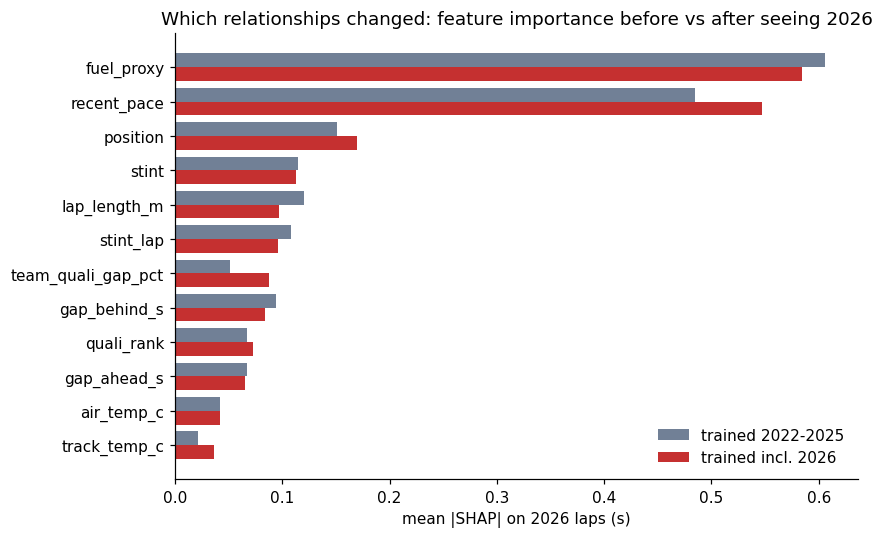

In [3]:
t = top.sort_values('incl_2026')
yy = np.arange(len(t)); h = 0.4
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(yy + h / 2, t['2022-2025'], height=h, label='trained 2022-2025', color='#718096')
ax.barh(yy - h / 2, t['incl_2026'], height=h, label='trained incl. 2026', color='#c53030')
ax.set_yticks(yy); ax.set_yticklabels(t.index); ax.set_xlabel('mean |SHAP| on 2026 laps (s)')
ax.set_title('Which relationships changed: feature importance before vs after seeing 2026')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/08_shap_comparison.png', dpi=150); plt.show()

**Figure 08.** The model now leans on **measured pace**. On 2026 laps the biggest attributions are `fuel_proxy` (laps of fuel on board) and `recent_pace` (how fast the driver has been over the last few laps), and once 2026 is in training the two features that gain the most are `recent_pace` (+0.06 s) and `team_quali_gap_pct` (+0.04 s, nearly doubling), both measurements re-taken every weekend. `position`, which dominated our first iteration, now carries a third of the attribution it used to (0.15 vs 0.47 s): it was mostly a stand-in for car pace, and the measurement features now carry that signal directly. Note that the "incl. 2026" model is explained on laps it was trained on, so this is an attribution comparison, not a test score.